# 확률·통계 — 손실 함수는 '고른 것'이 아니라 '가정에서 나온 것'

| 원문 | 내용 | 절 |
|---|---|---|
| 5-1 | 정규분포 N(0,1) · N(2,0.5) PDF 를 하나의 Figure에 | §1 |
| 5-2 | 베르누이 B(0.3) · B(0.7) PMF 막대그래프를 하나의 Figure에 | §1 |
| 5-3 | softmax 구현, 출력 합과 1.0 의 차이 ≤ 1e-6 | §4 |
| 5-4 | "MSE 최소화 = 정규분포 가정 하의 MLE" 수식 유도 | §2 |
| 5-5 | "Cross-Entropy 최소화 = 베르누이/카테고리 분포 가정 하의 MLE" 수식 유도 | §3 |

## §1. 분포 시각화 (원문 5-1 · 5-2)

정규분포 PDF $\;p(x\mid\mu,\sigma) = \dfrac{1}{\sigma\sqrt{2\pi}}\exp\!\Big(-\dfrac{(x-\mu)^2}{2\sigma^2}\Big)$,
베르누이 PMF $\;P(X=k\mid p) = p^k(1-p)^{1-k},\ k\in\{0,1\}$.

**표기 주의 — N(2, 0.5)**: 통계 교재의 $N(\mu,\sigma^2)$ 표기라면 0.5 는 **분산**(σ≈0.7071)이고, `numpy.random.normal(loc, scale)`
·`scipy.stats.norm(loc, scale)` 관례라면 **표준편차**(σ=0.5)다. 원문은 어느 쪽인지 밝히지 않는다.
이 노트북의 주 그림은 **σ = 0.5**(코드 관례, 그림 06 과 같음)로 그리고, 분산 해석(σ²=0.5)은 바로 아래 대조 그림에 둔다.
§2 의 유도는 $N(0,\sigma^2)$ (분산 표기)를 쓴다 — 두 절의 표기가 다르다는 것을 여기서 미리 밝혀 둔다.

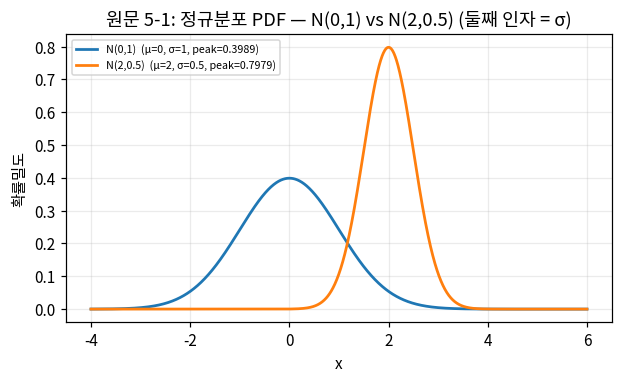

N(0,1): σ=1.0  peak=0.398942  ∫[-4,6]=0.999968
N(2,0.5): σ=0.5  peak=0.797885  ∫[-4,6]=1.000000


In [1]:
import numpy as np, json, pathlib, sys
import matplotlib.pyplot as plt
from IPython import display as _ipd
sys.path.insert(0, str(pathlib.Path.cwd() / 'src'))
import probability as P          # normal_pdf · bernoulli_pmf · softmax · fig_to_png_bytes
show = lambda fig: _ipd.display(_ipd.Image(data=P.fig_to_png_bytes(fig), format='png'))

x = np.linspace(-4, 6, 2001)
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for label, (mu, s) in P.NORMALS.items():
    ax.plot(x, P.normal_pdf(x, mu, s), lw=1.8, label=f'{label}  (μ={mu:g}, σ={s:g}, peak={P.normal_pdf(mu, mu, s):.4f})')
ax.set_title('원문 5-1: 정규분포 PDF — N(0,1) vs N(2,0.5) (둘째 인자 = σ)'); ax.set_xlabel('x'); ax.set_ylabel('확률밀도')
ax.legend(fontsize=7); ax.grid(alpha=.25); show(fig)
for label, (mu, s) in P.NORMALS.items():
    print(f'{label}: σ={s}  peak={P.normal_pdf(mu, mu, s):.6f}  ∫[-4,6]={np.trapezoid(P.normal_pdf(x, mu, s), x):.6f}')

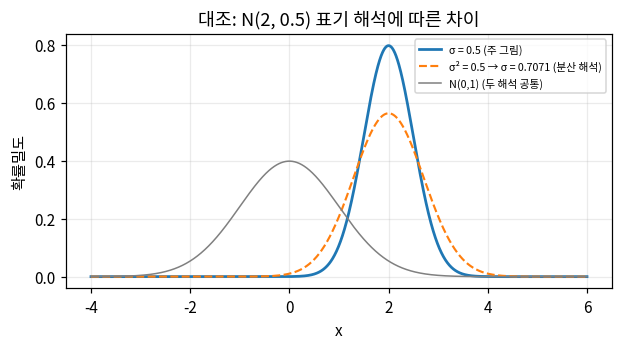

peak σ=0.5: 0.797885  / peak σ²=0.5: 0.56419


In [2]:
# 대조: N(2, ·) 의 두 해석 — σ=0.5 vs σ²=0.5 (σ≈0.7071)
fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.plot(x, P.normal_pdf(x, 2.0, 0.5), lw=1.8, label='σ = 0.5 (주 그림)')
ax.plot(x, P.normal_pdf(x, 2.0, np.sqrt(0.5)), lw=1.4, ls='--', label='σ² = 0.5 → σ = 0.7071 (분산 해석)')
ax.plot(x, P.normal_pdf(x, 0.0, 1.0), lw=1.0, c='0.5', label='N(0,1) (두 해석 공통)')
ax.set_title('대조: N(2, 0.5) 표기 해석에 따른 차이'); ax.set_xlabel('x'); ax.set_ylabel('확률밀도'); ax.legend(fontsize=7)
ax.grid(alpha=.25); show(fig)
print('peak σ=0.5:', round(float(P.normal_pdf(2, 2, 0.5)), 6), ' / peak σ²=0.5:', round(float(P.normal_pdf(2, 2, np.sqrt(0.5))), 6))

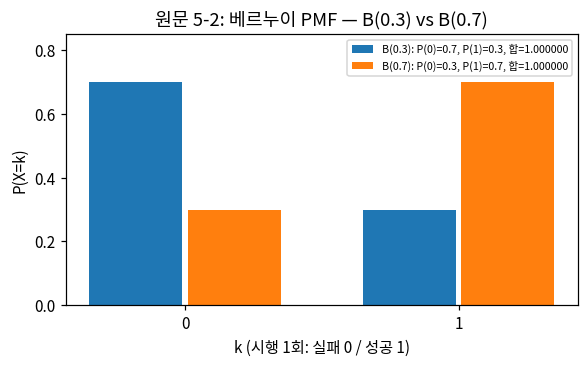

B(0.3) PMF = [0.7, 0.3]  합-1 = 0.0
B(0.7) PMF = [0.3, 0.7]  합-1 = 0.0


In [3]:
k = np.array([0, 1])
fig, ax = plt.subplots(figsize=(6.0, 3.2))
for i, (label, p) in enumerate(P.BERNOULLIS.items()):
    pmf = P.bernoulli_pmf(p)
    ax.bar(k + (-0.18 if i == 0 else 0.18), pmf, width=.34, label=f'{label}: P(0)={pmf[0]:.1f}, P(1)={pmf[1]:.1f}, 합={pmf.sum():.6f}')
ax.set_xticks([0, 1]); ax.set_ylim(0, .85); ax.set_title('원문 5-2: 베르누이 PMF — B(0.3) vs B(0.7)')
ax.set_xlabel('k (시행 1회: 실패 0 / 성공 1)'); ax.set_ylabel('P(X=k)'); ax.legend(fontsize=7); show(fig)
for label, p in P.BERNOULLIS.items():
    print(label, 'PMF =', np.round(P.bernoulli_pmf(p), 6).tolist(), ' 합-1 =', abs(P.bernoulli_pmf(p).sum() - 1.0))

## §2. MSE 최소화 = 정규분포 가정 하의 MLE (원문 5-4)

**가정**: $y_i = f_\theta(x_i) + \varepsilon_i,\quad \varepsilon_i \overset{iid}{\sim} N(0, \sigma^2)$ ($\sigma$ 는 θ 와 무관한 상수)

**1단계 — 한 샘플의 우도**: $\;p(y_i\mid x_i;\theta) = \dfrac{1}{\sqrt{2\pi\sigma^2}}\exp\!\Big(-\dfrac{(y_i - f_\theta(x_i))^2}{2\sigma^2}\Big)$

**2단계 — 독립이므로 곱**: $\;\mathcal L(\theta) = \prod_{i=1}^{N} p(y_i\mid x_i;\theta)$

**3단계 — 로그(단조증가라 argmax 불변)**:

$$\log\mathcal L(\theta) = \sum_{i=1}^N\Big[-\tfrac12\log(2\pi\sigma^2) - \frac{(y_i - f_\theta(x_i))^2}{2\sigma^2}\Big]
= \underbrace{-\tfrac N2\log(2\pi\sigma^2)}_{\theta\ \text{무관 상수}} \;-\; \frac{1}{2\sigma^2}\sum_{i=1}^N (y_i - f_\theta(x_i))^2$$

**4단계 — 최대화 ⇔ 최소화**: 상수항은 argmax 에 영향이 없고 $\frac{1}{2\sigma^2}>0$ 은 양의 배율이므로

$$\hat\theta_{MLE} = \arg\max_\theta \log\mathcal L(\theta) = \arg\min_\theta \sum_i (y_i - f_\theta(x_i))^2 = \arg\min_\theta \underbrace{\frac1N\sum_i (y_i - f_\theta(x_i))^2}_{\text{MSE}}$$

**5단계 — 해석**: MSE 는 "오차가 정규분포"라는 가정의 음의 로그우도(NLL)를 상수배·상수합만큼 바꾼 것이다.
가정이 깨지면(예: 오차가 라플라스 분포) 같은 논리로 MAE 가 MLE 가 된다. 또 σ 를 함께 추정하면 $\hat\sigma^2 = \text{MSE}(\hat\theta)$ 가 나온다.

In [4]:
# 수치 확인: 같은 격자(기울기 w, 0.001 간격) 위에서 MSE 최소점 = 정규 로그우도 최대점
d = json.loads(pathlib.Path('reports/probability.json').read_text(encoding='utf-8'))
print(json.dumps(d['MSE_MLE_동치'], ensure_ascii=False, indent=1))

{
 "기울기_MSE최소": 1.486,
 "기울기_로그우도최대": 1.486,
 "차이": "0.000e+00",
 "σ²_참값추정": 2.2366,
 "해석": "σ 고정 시 두 목적함수는 상수배·상수합의 관계 → 인자가 같다(정규화 상수는 기울기에 무영향)"
}


## §3. Cross-Entropy 최소화 = 베르누이 / 카테고리 분포 가정 하의 MLE (원문 5-5)

### 3-1. 이진 — 베르누이

**가정**: $y_i\in\{0,1\},\ y_i \sim \text{Bernoulli}(\hat p_i),\ \hat p_i = \sigma(z_i)$ (모델 출력)

**1단계**: $P(y_i\mid\hat p_i) = \hat p_i^{\,y_i}(1-\hat p_i)^{1-y_i}$  ($y_i=1$ 이면 $\hat p_i$, $0$ 이면 $1-\hat p_i$ — 한 식으로 쓴 것)

**2단계**: $\mathcal L = \prod_i \hat p_i^{\,y_i}(1-\hat p_i)^{1-y_i}$

**3단계**: $\log\mathcal L = \sum_i \big[y_i\log\hat p_i + (1-y_i)\log(1-\hat p_i)\big]$

**4단계**: $\displaystyle \arg\max\log\mathcal L = \arg\min\; -\frac1N\sum_i \big[y_i\log\hat p_i + (1-y_i)\log(1-\hat p_i)\big] = \arg\min \text{BCE}$

→ BCE 는 베르누이 음의 로그우도의 평균 그 자체다(상수항조차 없다). 역전파 노트북의 손실이 바로 이 식이다.

### 3-2. 다중 클래스 — 카테고리(categorical) 분포

**가정**: $y_i$ 는 C 개 클래스 중 하나, one-hot $\mathbf y_i\in\{0,1\}^C$; 모델은 $\hat{\mathbf p}_i = \text{softmax}(\mathbf z_i)$,
$\hat p_{i,c} = e^{z_{i,c}}/\sum_{c'} e^{z_{i,c'}}$ (합 1 — §4 에서 확인)

**1단계**: $P(\mathbf y_i\mid\hat{\mathbf p}_i) = \prod_{c=1}^C \hat p_{i,c}^{\,y_{i,c}}$ (정답 클래스의 확률만 남는다)

**2~3단계**: $\log\mathcal L = \sum_i\sum_c y_{i,c}\log\hat p_{i,c}$

**4단계**: $\displaystyle \arg\max\log\mathcal L = \arg\min\; -\frac1N\sum_i\sum_c y_{i,c}\log\hat p_{i,c} = \arg\min \text{CE}$

C=2 로 두면 $\hat p_{i,2} = 1-\hat p_{i,1}$ 이 되어 3-1 의 BCE 로 돌아온다(베르누이는 카테고리의 특수한 경우).

### 3-3. 정보이론 관점 (보너스 3 과 연결)

CE 를 경험분포 $q$ 와 모델 $p$ 의 교차엔트로피 $H(q,p) = -\sum q\log p = H(q) + D_{KL}(q\,\|\,p)$ 로 보면, $H(q)$ 는 θ 와 무관하므로
CE 최소화 = KL 최소화 = 우도 최대화.

In [5]:
# 수치 확인 1 — 베르누이: 로그우도 최대 p = BCE 최소 p (격자 0.00025)
print(json.dumps({k: v for k, v in d['CE_MLE_동치'].items() if k != '해석'}, ensure_ascii=False, indent=1))

# 수치 확인 2 — 카테고리: 3클래스 표본에서 categorical 로그우도 최대 p = CE 최소 p = 표본 빈도
rng = np.random.default_rng(P.RNG_SEED)
y = rng.choice(3, size=600, p=[0.2, 0.5, 0.3])
Y = np.eye(3)[y]                                     # one-hot (600,3)
counts = Y.sum(axis=0)
g = np.linspace(0.001, 0.998, 998)
best_ll, best_ce = (-np.inf, None), (np.inf, None)
for p1 in g:
    p2 = g[g < 1 - p1 - 1e-9]
    if not len(p2):
        continue
    p3 = 1 - p1 - p2
    ll = counts[0] * np.log(p1) + counts[1] * np.log(p2) + counts[2] * np.log(p3)     # Σ_i Σ_c y_ic log p_c
    ce = -ll / len(y)
    i = int(np.argmax(ll))
    if ll[i] > best_ll[0]:
        best_ll = (ll[i], (p1, p2[i], p3[i]))
    j = int(np.argmin(ce))
    if ce[j] < best_ce[0]:
        best_ce = (ce[j], (p1, p2[j], p3[j]))
print('표본 빈도      :', np.round(counts / len(y), 3).tolist())
print('logLik 최대 p  :', np.round(best_ll[1], 3).tolist())
print('CE 최소 p      :', np.round(best_ce[1], 3).tolist())
print('일치(격자 0.001):', np.allclose(best_ll[1], best_ce[1]) and np.allclose(best_ll[1], counts / len(y), atol=1e-3))

{
 "로그우도_최대의_p": 0.348,
 "BCE_최소의_p": 0.348,
 "차이": "0.000e+00",
 "표본_평균": 0.348,
 "플러그인_엔트로피": 0.6462,
 "진_엔트로피": 0.647447,
 "참값대_ fitted_교차엔트로피": 0.647455,
 "깁스_성립": true,
 "플러그인_편향": "-0.0012"
}
표본 빈도      : [0.223, 0.485, 0.292]
logLik 최대 p  : [0.223, 0.485, 0.292]
CE 최소 p      : [0.223, 0.485, 0.292]
일치(격자 0.001): True


## §4. softmax (원문 5-3)

$\text{softmax}(\mathbf z)_c = \dfrac{e^{z_c}}{\sum_{c'} e^{z_{c'}}} = \dfrac{e^{z_c - m}}{\sum_{c'} e^{z_{c'} - m}},\ m=\max_c z_c$
— 분자·분모에 같은 $e^{-m}$ 을 곱해도 값은 같고, 지수의 최댓값이 0 이 되어 overflow 가 없다.
합은 정의상 1 이지만 부동소수 합산 오차가 있으므로 원문은 $|\sum - 1| \le 10^{-6}$ 으로 확인하라고 한다.

In [6]:
def softmax(z):
    z = np.asarray(z, dtype=float)
    e = np.exp(z - z.max())
    return e / e.sum()

cases = {'[1,2,3]': [1., 2., 3.], '×1000': [1000., 2000., 3000.], '[-500,0,500]': [-500., 0., 500.],
         '난수 10차원(시드)': np.random.default_rng(P.RNG_SEED).normal(0, 5, 10)}
worst = 0.0
for name, z in cases.items():
    s = softmax(z); err = abs(s.sum() - 1.0); worst = max(worst, err)
    print(f'{name:16s} 출력={np.round(s, 6).tolist()}  |합-1|={err:.3e}  ≤1e-6: {err <= 1e-6}')
print('원문 5-3 통과:', worst <= 1e-6, '· 최대 |합-1| =', f'{worst:.3e}')
print('src/probability.softmax 와 동일:', all(np.allclose(softmax(z), P.softmax(z)) for z in cases.values()))
with np.errstate(over='ignore', invalid='ignore'):
    print('max 차감 없는 버전 ×1000 →', P.softmax(np.array([1000., 2000., 3000.]), stable=False), '(overflow → nan)')

[1,2,3]          출력=[0.090031, 0.244728, 0.665241]  |합-1|=1.110e-16  ≤1e-6: True
×1000            출력=[0.0, 0.0, 1.0]  |합-1|=0.000e+00  ≤1e-6: True
[-500,0,500]     출력=[0.0, 0.0, 1.0]  |합-1|=0.000e+00  ≤1e-6: True
난수 10차원(시드)      출력=[0.028589, 3.4e-05, 0.265519, 0.686944, 0.0, 9e-06, 0.011806, 0.001282, 0.005728, 8.8e-05]  |합-1|=1.110e-16  ≤1e-6: True
원문 5-3 통과: True · 최대 |합-1| = 1.110e-16
src/probability.softmax 와 동일: True
max 차감 없는 버전 ×1000 → [nan nan nan] (overflow → nan)


## §5. 덧붙임 — 정정 기록과 해석의 범위

- 이전 구현은 `p^k(1-p)^(10-k)`, k=0..10 을 '베르누이 PMF'라 그렸다(이항계수가 없어 합 ≠ 1, 확률분포가 아님). 지금은 k∈{0,1}.
  배우려던 이항분포 Binomial(10,p) 는 이름을 바로 붙여 아래에 대조로 둔다.
- 깁스 부등식 $H(q,p)\ge H(q)$ 는 **참 분포** 기준으로 성립한다. 표본의 플러그인 엔트로피는 아래로 편향되므로
  "학습 손실이 엔트로피보다 작으면 이상하다"는 표본 기준으로는 틀릴 수 있다(값은 아래 출력).

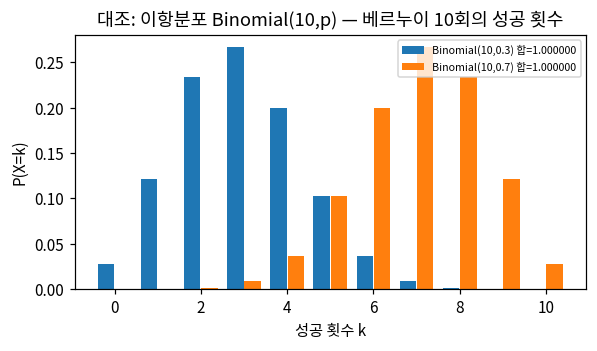

플러그인 엔트로피 0.6462 · 참 엔트로피 0.647447 · 편향 -0.0012 · 참분포 대비 CE 0.647455 · 깁스 성립 True


In [7]:
kk = np.arange(0, 11)
fig, ax = plt.subplots(figsize=(6.0, 3.0))
for p, off in ((0.3, -0.2), (0.7, 0.2)):
    ax.bar(kk + off, P.binomial_pmf(10, p), width=.38, label=f'Binomial(10,{p}) 합={P.binomial_pmf(10, p).sum():.6f}')
ax.set_title('대조: 이항분포 Binomial(10,p) — 베르누이 10회의 성공 횟수'); ax.set_xlabel('성공 횟수 k'); ax.set_ylabel('P(X=k)')
ax.legend(fontsize=7); show(fig)
c = d['CE_MLE_동치']
print('플러그인 엔트로피', c['플러그인_엔트로피'], '· 참 엔트로피', c['진_엔트로피'], '· 편향', c['플러그인_편향'],
      '· 참분포 대비 CE', c['참값대_ fitted_교차엔트로피'], '· 깁스 성립', c['깁스_성립'])